# HỌC VIỆN NGÂN HÀNG
### KHOA HỆ THỐNG THÔNG TIN QUẢN LÝ 
---
# BÀI TẬP THỰC HÀNH: TIỀN XỬ LÝ DỮ LIỆU HỒ SƠ VAY VỐN BẰNG PYTHON

* **Học phần:** Phân tích kinh doanh 
* **Sinh viên thực hiện:** Đỗ Văn Đạt
* **Công cụ sử dụng:** Python 3, `pandas`, `numpy`, `matplotlib`, `seaborn`, `openpyxl`
* **Mục tiêu:**
  1. Gộp dữ liệu từ nhiều nguồn: nối dọc (thêm quan sát) và nối ngang (thêm biến) bằng `pandas`.
  2. Phát hiện và xử lý dữ liệu thiếu, giá trị bất thường, giá trị ngoại lai.
  3. Tạo biến mới có ý nghĩa nghiệp vụ từ các biến gốc (Feature Engineering).
  4. Tóm tắt dữ liệu theo nhóm và rút ra nhận định phục vụ ra quyết định tín dụng.
  5. Chuẩn bị bộ dữ liệu sạch (`aplication_clean.xlsx`), sẵn sàng cho bước xây dựng mô hình chấm điểm tín dụng (Credit Scoring).


## 0. KHỞI TẠO MÔI TRƯỜNG VÀ CÁC THƯ VIỆN CẦN THIẾT

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
import warnings
warnings.filterwarnings('ignore')

# Cấu hình định dạng hiển thị
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.4f' % x)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['axes.unicode_minus'] = False

print("Đã nạp đầy đủ các thư viện cần thiết!")


Đã nạp đầy đủ các thư viện cần thiết!


---
# PHẦN 1. GỘP DỮ LIỆU VÀ KHÁM PHÁ BAN ĐẦU


### Câu 1.1. Đọc file `aplication1.xlsx` và `aplication2.xlsx`
* **Yêu cầu:** Đọc hai file dữ liệu. Cho biết số dòng và số cột của mỗi file. Kiểm tra xem hai file có cùng danh sách cột và cùng thứ tự cột hay không.


In [2]:
# Đọc hai file dữ liệu hồ sơ vay từ hai chi nhánh
df1 = pd.read_excel('aplication1.xlsx')
df2 = pd.read_excel('aplication2.xlsx')

print(f"File aplication1.xlsx: {df1.shape[0]:,} dòng, {df1.shape[1]} cột")
print(f"File aplication2.xlsx: {df2.shape[0]:,} dòng, {df2.shape[1]} cột")

# Kiểm tra danh sách cột và thứ tự cột
is_same_columns = list(df1.columns) == list(df2.columns)
print(f"Hai file có cùng danh sách cột và cùng thứ tự cột: {is_same_columns}")


File aplication1.xlsx: 6,920 dòng, 18 cột
File aplication2.xlsx: 10,970 dòng, 18 cột
Hai file có cùng danh sách cột và cùng thứ tự cột: True


**Kết quả:**
- File `aplication1.xlsx`: **6,920** dòng và **18** cột.
- File `aplication2.xlsx`: **10,970** dòng và **18** cột.
- Hai file hoàn toàn **cùng danh sách 18 cột và cùng thứ tự cột**.


### Câu 1.2. Nối DỌC hai file thành một bảng duy nhất (`aplication`)
* **Yêu cầu:** Nối DỌC hai file thành bảng `aplication`, đánh lại chỉ số dòng (`ignore_index=True`), xuất ra file `aplication.xlsx`. Cho biết số dòng sau khi nối và giải thích vì sao dùng `pd.concat` chứ không dùng `merge`.


In [3]:
# Nối dọc hai bảng dữ liệu
aplication = pd.concat([df1, df2], ignore_index=True)
print(f"Số dòng bảng aplication sau khi nối dọc: {aplication.shape[0]:,} dòng, {aplication.shape[1]} cột")

# Xuất ra file aplication.xlsx
aplication.to_excel('aplication.xlsx', index=False)
print("Đã xuất thành công ra file aplication.xlsx")


Số dòng bảng aplication sau khi nối dọc: 17,890 dòng, 18 cột


Đã xuất thành công ra file aplication.xlsx


**Kết quả:**
- Số dòng sau khi nối dọc: **17,890** dòng (tổng của 6,920 + 10,970) và **18** cột.

**Giải thích:**
- **`pd.concat` (Union / Append):** Dùng để **nối DỌC** (ghép thêm các dòng quan sát mới) khi hai tập dữ liệu có cùng cấu trúc cột và phản ánh cùng một loại đối tượng (ở đây là hồ sơ khách hàng vay vốn từ Chi nhánh 1 và Chi nhánh 2).
- **`pd.merge` (Join):** Dùng để **nối NGANG** (ghép thêm các biến/cột thông tin mới) dựa trên một hoặc nhiều khóa chung (foreign key) giữa các bảng có cấu trúc thông tin khác nhau. Nếu dùng `merge` trong trường hợp này sẽ không đúng bản chất vì hai file không phải là hai bảng quan hệ mà là hai phần của cùng một bảng dữ liệu.


### Câu 1.3. Kiểm tra trùng lặp mã hồ sơ `SK_ID_CURR`
* **Yêu cầu:** Kiểm tra xem mã hồ sơ `SK_ID_CURR` có bị trùng lặp sau khi nối hay không. Nếu có thì phải xử lý thế nào?


In [4]:
# Kiểm tra số lượng mã SK_ID_CURR bị trùng lặp
num_duplicates = aplication['SK_ID_CURR'].duplicated().sum()
print(f"Số lượng mã hồ sơ SK_ID_CURR bị trùng lặp: {num_duplicates}")


Số lượng mã hồ sơ SK_ID_CURR bị trùng lặp: 0


**Kết quả:**
- Số lượng mã hồ sơ bị trùng lặp là **0** (tất cả 17,890 mã hồ sơ `SK_ID_CURR` đều là duy nhất).

**Cách xử lý nếu có trùng:**
- **Trường hợp trùng lặp hoàn toàn cả dòng:** Sử dụng lệnh `aplication.drop_duplicates(inplace=True)` để giữ lại duy nhất 1 bản ghi đại diện.
- **Trường hợp trùng mã ID nhưng khác thông tin:** Cần đối soát lại với nguồn dữ liệu/hệ thống core banking để xác định lý do (khách hàng cập nhật hồ sơ hay lỗi hệ thống phát sinh trùng mã); có thể giữ lại hồ sơ mới nhất (`keep='last'`) hoặc tách mã/báo cáo bộ phận quản trị dữ liệu.


### Câu 1.4. In kiểu dữ liệu và đếm số biến định lượng / định tính
* **Yêu cầu:** In kiểu dữ liệu của tất cả các cột. Đếm xem có bao nhiêu biến định lượng và bao nhiêu biến định tính.


In [5]:
print("=== KIỂU DỮ LIỆU CỦA TẤT CẢ CÁC CỘT ===")
print(aplication.dtypes)

# Phân loại biến
cat_cols = [c for c in aplication.columns if aplication[c].dtype in ['object', 'category', 'string']]
num_cols = [c for c in aplication.columns if c not in cat_cols and c != 'SK_ID_CURR']

print("\n" + "="*50)
print(f"Số biến định tính: {len(cat_cols)} biến -> {cat_cols}")
print(f"Số biến định lượng: {len(num_cols)} biến (không tính khóa chính ID) -> {num_cols}")
print(f"Biến định danh (Identifier): 1 biến (SK_ID_CURR)")


=== KIỂU DỮ LIỆU CỦA TẤT CẢ CÁC CỘT ===
SK_ID_CURR                      int64
NAME_CONTRACT_TYPE                str
CODE_GENDER                       str
FLAG_OWN_CAR                      str
FLAG_OWN_REALTY                   str
CNT_CHILDREN                    int64
AMT_INCOME_TOTAL              float64
AMT_CREDIT                    float64
AMT_ANNUITY                   float64
AMT_GOODS_PRICE               float64
NAME_TYPE_SUITE                   str
NAME_INCOME_TYPE                  str
NAME_EDUCATION_TYPE               str
NAME_FAMILY_STATUS                str
NAME_HOUSING_TYPE                 str
REGION_POPULATION_RELATIVE    float64
DAYS_BIRTH                      int64
DAYS_EMPLOYED                   int64
dtype: object

Số biến định tính: 9 biến -> ['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE']
Số biến định lượng: 8 biến (không tính khóa chính ID) 

**Kết quả:**
- **Số biến định tính (9 biến):** `NAME_CONTRACT_TYPE`, `CODE_GENDER`, `FLAG_OWN_CAR`, `FLAG_OWN_REALTY`, `NAME_TYPE_SUITE`, `NAME_INCOME_TYPE`, `NAME_EDUCATION_TYPE`, `NAME_FAMILY_STATUS`, `NAME_HOUSING_TYPE`.
- **Số biến định lượng (8 biến):** `CNT_CHILDREN`, `AMT_INCOME_TOTAL`, `AMT_CREDIT`, `AMT_ANNUITY`, `AMT_GOODS_PRICE`, `REGION_POPULATION_RELATIVE`, `DAYS_BIRTH`, `DAYS_EMPLOYED` *(Lưu ý: Nếu tính cả cột định danh `SK_ID_CURR` lưu dưới dạng int64 thì có 9 biến kiểu số)*.


---
# PHẦN 2. XỬ LÝ DỮ LIỆU THIẾU


### Câu 2.1. Thống kê dữ liệu thiếu
* **Yêu cầu:** Lập bảng thống kê số ô thiếu và tỷ lệ % thiếu của từng cột, chỉ hiển thị những cột thực sự có dữ liệu thiếu.


In [6]:
missing = aplication.isna().sum()
missing_nonzero = missing[missing > 0]
missing_table = pd.DataFrame({
    'Số ô thiếu': missing_nonzero,
    'Tỷ lệ % thiếu': (missing_nonzero / len(aplication) * 100).round(2)
})
print("Bảng thống kê các cột có dữ liệu thiếu:")
display(missing_table)


Bảng thống kê các cột có dữ liệu thiếu:


,Số ô thiếu,Tỷ lệ % thiếu
AMT_ANNUITY,8,0.0400
NAME_TYPE_SUITE,325,1.8200


**Kết quả:**
- Cột thiếu thứ nhất: `AMT_ANNUITY` có **8** ô thiếu (chiếm **0.04%**).
- Cột thiếu thứ hai: `NAME_TYPE_SUITE` có **325** ô thiếu (chiếm **1.82%**).


### Câu 2.2. Điền dữ liệu thiếu của `AMT_ANNUITY` bằng TRUNG VỊ
* **Yêu cầu:** Điền dữ liệu thiếu của `AMT_ANNUITY` bằng TRUNG VỊ. Cho biết giá trị trung vị đã dùng và giải thích: vì sao với biến tiền tệ nên dùng trung vị thay vì trung bình?


In [7]:
# Tính trung vị và điền khuyết
med_annuity = aplication['AMT_ANNUITY'].median()
print(f"Giá trị trung vị của AMT_ANNUITY: {med_annuity:,.2f}")

aplication['AMT_ANNUITY'] = aplication['AMT_ANNUITY'].fillna(med_annuity)
print(f"Số ô thiếu còn lại của AMT_ANNUITY: {aplication['AMT_ANNUITY'].isna().sum()}")


Giá trị trung vị của AMT_ANNUITY: 25,839.00
Số ô thiếu còn lại của AMT_ANNUITY: 0


**Kết quả:**
- Giá trị trung vị đã dùng: **25,839.0**

**Giải thích:**
- Các biến tiền tệ trong tài chính (như số tiền trả góp định kỳ `AMT_ANNUITY`, thu nhập `AMT_INCOME_TOTAL`, hạn mức vay `AMT_CREDIT`) thường có phân phối **lệch phải mạnh (right-skewed)** với sự xuất hiện của các giá trị cực lớn (outliers).
- Giá trị trung bình (mean) rất nhạy cảm với các giá trị ngoại lai này và sẽ bị kéo lệch lên cao, không phản ánh đúng mức trả nợ phổ biến của đa số khách hàng thông thường.
- Trong khi đó, **trung vị (median)** là đại lượng thống kê vững (robust statistic), không bị ảnh hưởng bởi các giá trị cực đoan, giúp bảo toàn tính đại diện cho xu hướng trung tâm của tệp khách hàng.


### Câu 2.3. Điền dữ liệu thiếu của `NAME_TYPE_SUITE` bằng giá trị "Unknown"
* **Yêu cầu:** Điền dữ liệu thiếu của `NAME_TYPE_SUITE` bằng giá trị "Unknown". Giải thích vì sao KHÔNG nên xóa các dòng thiếu này.


In [8]:
# Điền giá trị thiếu của biến định tính bằng 'Unknown'
aplication['NAME_TYPE_SUITE'] = aplication['NAME_TYPE_SUITE'].fillna('Unknown')
print(f"Số lượng hồ sơ mang giá trị 'Unknown' trong NAME_TYPE_SUITE: {(aplication['NAME_TYPE_SUITE'] == 'Unknown').sum()}")


Số lượng hồ sơ mang giá trị 'Unknown' trong NAME_TYPE_SUITE: 325


**Giải thích:**
1. **Tránh mất mát thông tin quan trọng:** Tỷ lệ thiếu của biến này rất nhỏ (chỉ 1.82%, 325 hồ sơ). Nếu xóa các dòng này, ta sẽ vô tình xóa bỏ toàn bộ thông tin tài chính cốt lõi khác của khách hàng (như thu nhập, số tiền vay, lịch sử tín dụng).
2. **Ngăn ngừa chệch mẫu (Selection Bias):** Việc khách hàng không khai báo người đi cùng có thể mang một đặc trưng hành vi riêng (ví dụ: người đi vay độc lập). Việc gán nhãn `"Unknown"` tạo thành một nhóm riêng biệt giúp mô hình máy học tiếp tục khai thác được đặc trưng này mà không làm giảm dung lượng dữ liệu huấn luyện.


### Câu 2.4. Kiểm tra lại tổng số ô thiếu
* **Yêu cầu:** Kiểm tra lại tổng số ô thiếu trong toàn bộ bảng để xác nhận đã xử lý xong.


In [9]:
total_missing_after = aplication.isna().sum().sum()
print(f"Tổng số ô thiếu trong toàn bộ bảng aplication sau xử lý: {total_missing_after}")


Tổng số ô thiếu trong toàn bộ bảng aplication sau xử lý: 0


**Kết quả:**
- Tổng số ô thiếu còn lại: **0** (toàn bộ dữ liệu thiếu đã được xử lý triệt để).


---
# PHẦN 3. GIÁ TRỊ BẤT THƯỜNG VÀ NGOẠI LAI


### Câu 3.1. Tìm giá trị bất thường của `DAYS_EMPLOYED`
* **Yêu cầu:** Theo quy ước, `DAYS_EMPLOYED` phải mang giá trị âm. Hãy tìm giá trị lớn nhất của biến này và đếm xem có bao nhiêu dòng mang giá trị bất thường đó, chiếm bao nhiêu phần trăm tổng số hồ sơ.


In [10]:
max_days_employed = aplication['DAYS_EMPLOYED'].max()
anomaly_rows = (aplication['DAYS_EMPLOYED'] == 365243).sum()
anomaly_rate = (anomaly_rows / len(aplication)) * 100

print(f"Giá trị lớn nhất của DAYS_EMPLOYED: {max_days_employed}")
print(f"Số dòng mang giá trị bất thường (365243): {anomaly_rows:,} dòng")
print(f"Tỷ lệ chiếm: {anomaly_rate:.2f}% tổng số hồ sơ")


Giá trị lớn nhất của DAYS_EMPLOYED: 365243
Số dòng mang giá trị bất thường (365243): 3,380 dòng
Tỷ lệ chiếm: 18.89% tổng số hồ sơ


**Kết quả:**
- Giá trị bất thường lớn nhất: **365,243** (dương 365,243 ngày ~ 1,000 năm).
- Số dòng mang giá trị bất thường: **3,380** dòng, chiếm **18.89%** tổng số hồ sơ.


### Câu 3.2. Nhóm hồ sơ bất thường và ý nghĩa con số 365243
* **Yêu cầu:** Nhóm hồ sơ bất thường này chủ yếu thuộc loại `NAME_INCOME_TYPE` nào? Từ đó giải thích ý nghĩa nghiệp vụ của con số 365243.


In [11]:
# Khảo sát phân bố nguồn thu nhập của nhóm hồ sơ có DAYS_EMPLOYED bất thường (365243)
anomaly_mask = (aplication['DAYS_EMPLOYED'] == 365243)
anomaly_income_dist = aplication[anomaly_mask]['NAME_INCOME_TYPE'].value_counts()

print("Phân bố nguồn thu nhập của nhóm hồ sơ có giá trị DAYS_EMPLOYED bất thường (365243):")
print(anomaly_income_dist)


Phân bố nguồn thu nhập của nhóm hồ sơ có giá trị DAYS_EMPLOYED bất thường (365243):
NAME_INCOME_TYPE
Pensioner    3380
Name: count, dtype: int64


**Kết quả & Ý nghĩa nghiệp vụ:**
- **Nhóm chiếm đa số:** 100% trong số 3,380 hồ sơ bất thường đều thuộc nhóm **`Pensioner` (Người về hưu)**.
- **Ý nghĩa nghiệp vụ của con số 365243:** Con số `365243` là một **mã quy ước kỹ thuật (sentinel value / placeholder code)** được hệ thống core banking thiết lập tự động để biểu thị trạng thái "Không đi làm / Đã nghỉ hưu / Không áp dụng số ngày làm việc" ($365.2425 \text{ ngày} \times 1000 \text{ năm} \approx 365,243$), chứ không phải khách hàng đã đi làm 1,000 năm.


### Câu 3.3. Thay toàn bộ giá trị bất thường bằng `NaN`
* **Yêu cầu:** Thay toàn bộ giá trị bất thường đó bằng `NaN`. Cho biết vì sao lựa chọn này tốt hơn việc xóa các dòng đó.


In [12]:
# Thay giá trị bất thường 365243 bằng np.nan
aplication['DAYS_EMPLOYED'] = aplication['DAYS_EMPLOYED'].replace(365243, np.nan)
print(f"Số lượng giá trị NaN trong DAYS_EMPLOYED sau khi thay thế: {aplication['DAYS_EMPLOYED'].isna().sum():,}")


Số lượng giá trị NaN trong DAYS_EMPLOYED sau khi thay thế: 3,380


**Giải thích:**
- Nhóm bất thường này chiếm tới **18.89%** tổng tệp dữ liệu (3,380 khách hàng).
- Nếu xóa các dòng này, ta sẽ loại bỏ hoàn toàn gần như toàn bộ phân khúc khách hàng hưu trí (`Pensioner`), làm mất gần 1/5 dung lượng dữ liệu và làm méo mó nghiêm trọng cơ cấu mẫu khách hàng của ngân hàng.
- Việc thay bằng `np.nan` giúp loại bỏ giá trị dương 365,243 gây sai lệch các phép tính thống kê (như tính số năm đi làm trung bình), đồng thời vẫn giữ lại toàn bộ các thông tin quan trọng khác của người về hưu để phân tích và đánh giá tín dụng.


### Câu 3.4. Phát hiện ngoại lai biến `AMT_INCOME_TOTAL` bằng quy tắc IQR
* **Yêu cầu:** Dùng quy tắc IQR để phát hiện ngoại lai của biến `AMT_INCOME_TOTAL`: tính Q1, Q3, IQR, cận dưới, cận trên và đếm số hồ sơ nằm ngoài khoảng đó. Nêu quan điểm: có nên xóa các hồ sơ này khỏi bộ dữ liệu không? Vì sao?


In [13]:
q1 = aplication['AMT_INCOME_TOTAL'].quantile(0.25)
q3 = aplication['AMT_INCOME_TOTAL'].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = aplication[(aplication['AMT_INCOME_TOTAL'] < lower_bound) | (aplication['AMT_INCOME_TOTAL'] > upper_bound)]

print(f"Tứ phân vị thứ nhất Q1 (25%): {q1:,.2f}")
print(f"Tứ phân vị thứ ba Q3 (75%):   {q3:,.2f}")
print(f"Khoảng tứ phân vị IQR:       {iqr:,.2f}")
print(f"Cận dưới (Lower Bound):       {lower_bound:,.2f}")
print(f"Cận trên (Upper Bound):       {upper_bound:,.2f}")
print(f"Số lượng hồ sơ ngoại lai:     {len(outliers):,} hồ sơ ({len(outliers)/len(aplication)*100:.2f}% tổng số hồ sơ)")


Tứ phân vị thứ nhất Q1 (25%): 112,500.00
Tứ phân vị thứ ba Q3 (75%):   225,000.00
Khoảng tứ phân vị IQR:       112,500.00
Cận dưới (Lower Bound):       -56,250.00
Cận trên (Upper Bound):       393,750.00
Số lượng hồ sơ ngoại lai:     573 hồ sơ (3.20% tổng số hồ sơ)


**Kết quả:**
- $Q_1 = 112,500.0$, $Q_3 = 225,000.0$, $IQR = 112,500.0$
- Cận dưới: **-56,250.0** (Thu nhập thực tế không âm, nên không có hồ sơ nào dưới cận dưới).
- Cận trên: **393,750.0**
- Số hồ sơ ngoại lai: **573** hồ sơ (chiếm **3.20%** tổng số hồ sơ, đều có thu nhập > 393,750).

**Quan điểm:** **KHÔNG NÊN XÓA** các hồ sơ này khỏi bộ dữ liệu.
**Vì sao:**
1. **Giá trị thực tế hợp lý:** Thu nhập cao là hiện tượng hoàn toàn tự nhiên và có thực trong nền kinh tế (doanh nhân, chuyên gia, quản lý cấp cao), không phải do lỗi gõ sai dữ liệu (data entry error).
2. **Khách hàng mục tiêu giá trị cao:** Trong hoạt động ngân hàng, khách hàng thu nhập cao thuộc phân khúc khách hàng ưu tiên (Affluent / VIP) mang lại lợi nhuận và hạn mức tín dụng lớn. Xóa bỏ họ sẽ làm mất đi khả năng mô hình hóa phân khúc này.
3. **Giải pháp thay thế ưu việt:** Thay vì xóa bỏ gây mất mát dữ liệu, ta có thể áp dụng các kỹ thuật tiền xử lý tiên tiến như: biến đổi Logarit (`np.log1p`), kỹ thuật Winsorization (cắt ngưỡng ngoại lai), hoặc sử dụng các mô hình cây quyết định (Random Forest, XGBoost) có khả năng kháng ngoại lai rất tốt.


---
# PHẦN 4. TẠO BIẾN MỚI (FEATURE ENGINEERING)


### Câu 4.1 – 4.2. Tạo biến `AGE` và `YEARS_EMPLOYED`
* **Yêu cầu:** Tạo biến `AGE` (tuổi, làm tròn 1 chữ số thập phân) và `YEARS_EMPLOYED` (số năm đi làm) từ `DAYS_BIRTH` và `DAYS_EMPLOYED`. Cho biết tuổi nhỏ nhất, tuổi lớn nhất, tuổi trung bình và số năm đi làm trung bình.


In [14]:
# Tạo biến AGE và YEARS_EMPLOYED
aplication['AGE'] = (-aplication['DAYS_BIRTH'] / 365).round(1)
aplication['YEARS_EMPLOYED'] = -aplication['DAYS_EMPLOYED'] / 365

print(f"Tuổi nhỏ nhất:          {aplication['AGE'].min():.1f} tuổi")
print(f"Tuổi lớn nhất:          {aplication['AGE'].max():.1f} tuổi")
print(f"Tuổi trung bình:        {aplication['AGE'].mean():.2f} tuổi")
print(f"Số năm đi làm TB:       {aplication['YEARS_EMPLOYED'].mean():.2f} năm (tính trên nhóm đang đi làm)")


Tuổi nhỏ nhất:          21.0 tuổi
Tuổi lớn nhất:          68.7 tuổi
Tuổi trung bình:        44.05 tuổi
Số năm đi làm TB:       6.77 năm (tính trên nhóm đang đi làm)


**Kết quả:**
- Tuổi nhỏ nhất: **21.0** tuổi | Tuổi lớn nhất: **68.7** tuổi | Tuổi trung bình: **44.05** tuổi.
- Số năm đi làm trung bình: **6.77** năm.


### Câu 4.3. Tỷ lệ nợ trên thu nhập (`DTI`)
* **Yêu cầu:** Tạo biến `DTI = AMT_ANNUITY / AMT_INCOME_TOTAL`. Cho biết giá trị trung bình và giải thích ý nghĩa của chỉ tiêu này trong thẩm định tín dụng.


In [15]:
aplication['DTI'] = aplication['AMT_ANNUITY'] / aplication['AMT_INCOME_TOTAL']
print(f"Giá trị DTI trung bình: {aplication['DTI'].mean():.4f} ({aplication['DTI'].mean()*100:.2f}%)")


Giá trị DTI trung bình: 0.1830 (18.30%)


**Kết quả:**
- DTI trung bình: **0.1830** (tương đương **18.30%**).

**Ý nghĩa trong thẩm định tín dụng:**
- **DTI (Debt-to-Income Ratio)** là chỉ tiêu cốt lõi đo lường tỷ lệ phần trăm thu nhập hàng năm của khách hàng phải dành ra để thanh toán các nghĩa vụ trả nợ định kỳ.
- Trong thẩm định tín dụng, DTI phản ánh trực tiếp **năng lực trả nợ (capacity)** và độ an toàn tài chính của khách hàng. Tỷ lệ DTI ở mức 18.30% cho thấy nhìn chung khách hàng còn dư địa tài chính tốt để trang trải sinh hoạt và trả nợ. Nếu DTI quá cao (thông thường vượt quá 40% - 50%), khách hàng sẽ có nguy cơ rơi vào tình trạng quá tải nợ và có xác suất trễ hạn/vỡ nợ (Default Probability) cao hơn rõ rệt.


### Câu 4.4. Tỷ lệ khoản vay trên thu nhập (`CREDIT_INCOME_RATIO`)
* **Yêu cầu:** Tạo biến `CREDIT_INCOME_RATIO = AMT_CREDIT / AMT_INCOME_TOTAL` và cho biết giá trị trung bình.


In [16]:
aplication['CREDIT_INCOME_RATIO'] = aplication['AMT_CREDIT'] / aplication['AMT_INCOME_TOTAL']
print(f"Tỷ lệ khoản vay trên thu nhập trung bình: {aplication['CREDIT_INCOME_RATIO'].mean():.4f}")


Tỷ lệ khoản vay trên thu nhập trung bình: 3.1738


**Kết quả:**
- Giá trị trung bình: **3.1738** (khoản vay trung bình gấp khoảng **3.17 lần** tổng thu nhập năm của khách hàng).


### Câu 4.5. Phân nhóm độ tuổi (`AGE_GROUP`)
* **Yêu cầu:** Dùng `pd.cut` chia biến `AGE` thành 5 nhóm: dưới 30, 30–39, 40–49, 50–59, từ 60 trở lên. Cho biết số hồ sơ của từng nhóm.


In [17]:
bins = [0, 30, 40, 50, 60, np.inf]
labels = ['Dưới 30', '30–39', '40–49', '50–59', 'Từ 60 trở lên']
aplication['AGE_GROUP'] = pd.cut(aplication['AGE'], bins=bins, right=False, labels=labels)

age_summary = pd.DataFrame({
    'Số lượng hồ sơ': aplication['AGE_GROUP'].value_counts().sort_index(),
    'Tỷ lệ %': (aplication['AGE_GROUP'].value_counts(normalize=True).sort_index() * 100).round(2)
})
print("Phân bố hồ sơ theo từng nhóm tuổi:")
display(age_summary)


Phân bố hồ sơ theo từng nhóm tuổi:


,Số lượng hồ sơ,Tỷ lệ %
AGE_GROUP,,
Dưới 30,2502,13.9900
30–39,4800,26.8300
40–49,4505,25.1800
50–59,3999,22.3500
Từ 60 trở lên,2084,11.6500


**Kết quả:**
- Dưới 30 tuổi: **2,502** hồ sơ (13.99%)
- 30–39 tuổi: **4,800** hồ sơ (26.83%)
- 40–49 tuổi: **4,505** hồ sơ (25.18%)
- 50–59 tuổi: **3,999** hồ sơ (22.35%)
- Từ 60 trở lên: **2,084** hồ sơ (11.65%)


---
# PHẦN 5. THỐNG KÊ MÔ TẢ THEO NHÓM


### Câu 5.1. Số tiền vay trung bình theo nhóm tuổi
* **Yêu cầu:** Tính số tiền vay trung bình (`AMT_CREDIT`) theo từng nhóm tuổi `AGE_GROUP` và viết nhận xét về ý nghĩa đối với hoạt động cho vay.


In [18]:
credit_by_age = aplication.groupby('AGE_GROUP', observed=False)['AMT_CREDIT'].agg(
    Số_tiền_vay_TB='mean',
    Số_lượng_hồ_sơ='count'
)
display(credit_by_age)


,Số_tiền_vay_TB,Số_lượng_hồ_sơ
AGE_GROUP,,
Dưới 30,406170.5665,2502
30–39,512445.7134,4800
40–49,572233.1694,4505
50–59,557834.6849,3999
Từ 60 trở lên,442333.1919,2084


**Kết quả:**
- Dưới 30: **406,170.57**
- 30–39: **512,445.71**
- 40–49: **572,233.17** (Cao nhất)
- 50–59: **557,834.68**
- Từ 60 trở lên: **442,333.19**

**Nhận xét:**
Khách hàng ở độ tuổi trung niên (40–49 và 50–59 tuổi) có số tiền vay trung bình cao nhất do đây là độ tuổi chín muồi về sự nghiệp, thu nhập ổn định và có nhu cầu vay vốn lớn để tích lũy tài sản, đầu tư hoặc mua nhà; trong khi nhóm trẻ (<30) và nhóm lớn tuổi (>=60) vay ít hơn để phù hợp với thu nhập khởi điểm hoặc thu nhập hưu trí.


### Câu 5.2. Thu nhập trung bình và số hồ sơ theo giới tính
* **Yêu cầu:** Tính thu nhập trung bình theo giới tính `CODE_GENDER` và số hồ sơ của mỗi giới. Viết nhận xét.


In [19]:
gender_stats = aplication.groupby('CODE_GENDER')['AMT_INCOME_TOTAL'].agg(
    Số_hồ_sơ='count',
    Thu_nhập_TB='mean'
)
gender_stats['Tỷ lệ hồ sơ %'] = (gender_stats['Số_hồ_sơ'] / len(aplication) * 100).round(2)
display(gender_stats)


,Số_hồ_sơ,Thu_nhập_TB,Tỷ lệ hồ sơ %
CODE_GENDER,,,
F,11988,165861.2830,67.0100
M,5902,202108.4177,32.9900


**Kết quả:**
- Nữ (F): **11,988** hồ sơ (67.01%), Thu nhập trung bình: **165,861.28**
- Nam (M): **5,902** hồ sơ (32.99%), Thu nhập trung bình: **202,108.42**

**Nhận xét:**
Khách hàng nữ chiếm tỷ trọng áp đảo trong tổng số hồ sơ nộp vay (gấp hơn 2 lần nam giới), tuy nhiên thu nhập bình quân của khách hàng nam lại cao hơn khách hàng nữ khoảng 21.8%, phản ánh sự khác biệt về cơ cấu ngành nghề và phân khúc thu nhập giữa hai giới trong tệp khách hàng vay vốn của ngân hàng.


### Câu 5.3. Số hồ sơ và số tiền vay trung bình theo trình độ học vấn
* **Yêu cầu:** Tính số hồ sơ và số tiền vay trung bình theo trình độ học vấn `NAME_EDUCATION_TYPE`, sắp xếp theo số tiền vay trung bình giảm dần. Viết nhận xét.


In [20]:
edu_stats = aplication.groupby('NAME_EDUCATION_TYPE')['AMT_CREDIT'].agg(
    Số_hồ_sơ='count',
    Số_tiền_vay_TB='mean'
).sort_values(by='Số_tiền_vay_TB', ascending=False)

display(edu_stats)


,Số_hồ_sơ,Số_tiền_vay_TB
NAME_EDUCATION_TYPE,,
Academic degree,17,719929.5882
Higher education,4482,613066.5311
Secondary / secondary special,12573,482617.8651
Incomplete higher,619,476535.4386
Lower secondary,199,419894.6608


**Kết quả:**
1. `Academic degree`: **17** hồ sơ | Số tiền vay TB: **719,929.59**
2. `Higher education`: **4,482** hồ sơ | Số tiền vay TB: **613,066.53**
3. `Secondary / secondary special`: **12,573** hồ sơ | Số tiền vay TB: **482,617.87**
4. `Incomplete higher`: **619** hồ sơ | Số tiền vay TB: **476,535.44**
5. `Lower secondary`: **199** hồ sơ | Số tiền vay TB: **419,894.66**

**Nhận xét:**
Trình độ học vấn tỷ lệ thuận với số tiền vay bình quân (khách hàng có trình độ học vấn càng cao thì được cấp hạn mức vay càng lớn), chứng minh trình độ học vấn là một biến số phản ánh tiềm năng thu nhập, vị trí công tác và uy tín tín dụng quan trọng trong chính sách phê duyệt tín dụng của ngân hàng.


### Câu 5.4. So sánh DTI trung bình giữa nhóm có ô tô và không có ô tô
* **Yêu cầu:** So sánh DTI trung bình giữa nhóm có ô tô và không có ô tô (`FLAG_OWN_CAR`). Viết nhận xét.


In [21]:
car_stats = aplication.groupby('FLAG_OWN_CAR')['DTI'].agg(
    DTI_trung_bình='mean',
    Số_lượng_hồ_sơ='count'
)
display(car_stats)


,DTI_trung_bình,Số_lượng_hồ_sơ
FLAG_OWN_CAR,,
N,0.1866,11882
Y,0.1759,6008


**Kết quả:**
- Không sở hữu ô tô (N): DTI trung bình = **0.1866** (18.66%)
- Có sở hữu ô tô (Y): DTI trung bình = **0.1759** (17.59%)

**Nhận xét:**
Khách hàng sở hữu ô tô có tỷ lệ gánh nặng nợ trên thu nhập (DTI) thấp hơn nhóm không có ô tô, cho thấy nhóm sở hữu tài sản này có năng lực tạo thu nhập và tích lũy tài chính vượt trội hơn so với nghĩa vụ trả nợ, đây là nhóm khách hàng tiềm năng có mức độ rủi ro tín dụng thấp hơn.


### Câu 5.5. Trực quan hóa dữ liệu (Histogram & Boxplot)
* **Yêu cầu:** Vẽ biểu đồ histogram của biến `AGE` và boxplot của biến `AMT_INCOME_TOTAL`. Biểu đồ nào cho thấy rõ vấn đề ngoại lai đã phát hiện ở Câu 3.4?


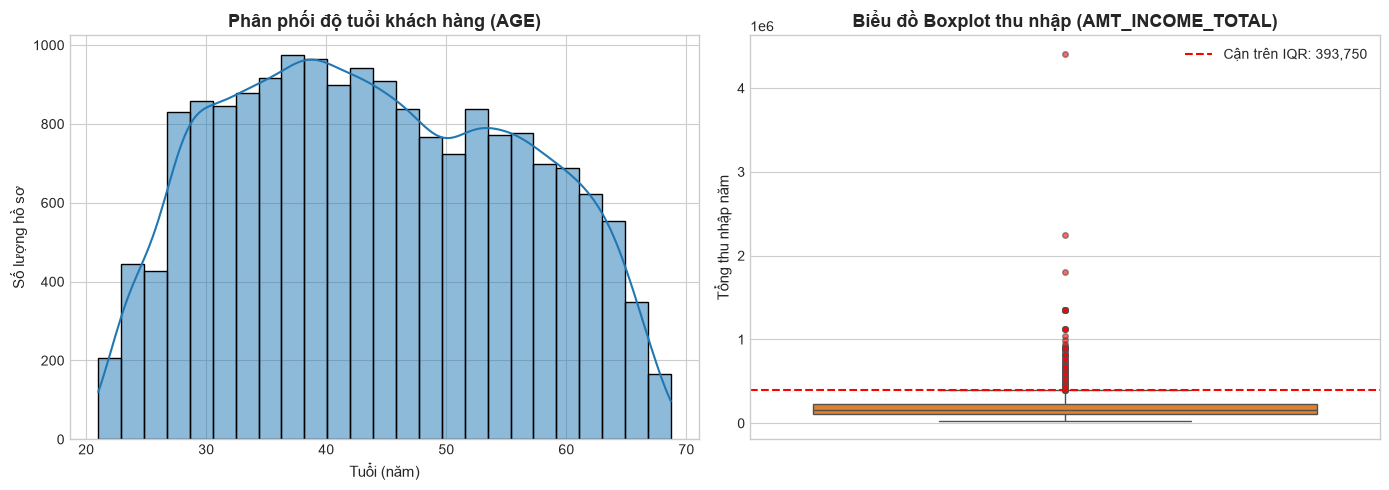

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Histogram biến AGE
sns.histplot(aplication['AGE'], kde=True, ax=axes[0], color='#1f77b4', bins=25, edgecolor='black')
axes[0].set_title('Phân phối độ tuổi khách hàng (AGE)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Tuổi (năm)', fontsize=11)
axes[0].set_ylabel('Số lượng hồ sơ', fontsize=11)

# 2. Boxplot biến AMT_INCOME_TOTAL
sns.boxplot(y=aplication['AMT_INCOME_TOTAL'], ax=axes[1], color='#ff7f0e', flierprops=dict(markerfacecolor='red', marker='o', markersize=4, alpha=0.6))
axes[1].axhline(upper_bound, color='red', linestyle='--', linewidth=1.5, label=f'Cận trên IQR: {upper_bound:,.0f}')
axes[1].set_title('Biểu đồ Boxplot thu nhập (AMT_INCOME_TOTAL)', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Tổng thu nhập năm', fontsize=11)
axes[1].legend(loc='upper right', fontsize=10)

plt.tight_layout()
plt.show()


**Trả lời:**
- Biểu đồ **Boxplot của biến `AMT_INCOME_TOTAL`** cho thấy rõ nhất vấn đề ngoại lai đã phát hiện ở Câu 3.4.
- Trên biểu đồ boxplot, các điểm dữ liệu thu nhập ngoại lai (màu đỏ) nằm dày đặc và kéo dài tít lên phía trên vượt xa đường cận trên $Q_3 + 1.5 \times IQR = 393,750$, thể hiện rõ độ lệch phải cực đoan của phân phối thu nhập.
- Ngược lại, biểu đồ histogram của biến `AGE` cho thấy phân phối trải tương đối đều đặn trong độ tuổi lao động (21 - 69 tuổi) và không hề xuất hiện giá trị ngoại lai dị biệt.


---
# PHẦN 6. NỐI VỚI BUREAU VÀ HOÀN THIỆN BỘ DỮ LIỆU


### Câu 6.1. Đọc file `bureau.csv` và kiểm tra quan hệ dữ liệu
* **Yêu cầu:** Đọc file `bureau.csv`. Cho biết số dòng, số cột. Đếm xem một mã `SK_ID_CURR` nhiều nhất xuất hiện bao nhiêu dòng trong bảng này và giải thích vì sao lại như vậy.


In [23]:
# Đọc file dữ liệu lịch sử tín dụng bureau.csv
bureau = pd.read_csv('bureau.csv')
print(f"File bureau.csv: {bureau.shape[0]:,} dòng, {bureau.shape[1]} cột")

max_curr_count = bureau['SK_ID_CURR'].value_counts().max()
max_curr_id = bureau['SK_ID_CURR'].value_counts().idxmax()
print(f"Một mã SK_ID_CURR nhiều nhất xuất hiện: {max_curr_count} dòng (Mã khách hàng: {max_curr_id})")


File bureau.csv: 980,316 dòng, 17 cột
Một mã SK_ID_CURR nhiều nhất xuất hiện: 116 dòng (Mã khách hàng: 120860)


**Kết quả:**
- File `bureau.csv` có **980,316** dòng và **17** cột.
- Một mã `SK_ID_CURR` xuất hiện nhiều nhất lên tới **116** dòng (mã khách hàng `120860`).

**Giải thích vì sao lại như vậy:**
- Bảng `bureau` lưu trữ lịch sử các khoản vay cũ của khách hàng tại tất cả các tổ chức tín dụng khác được Trung tâm Thông tin Tín dụng ghi nhận.
- Mối quan hệ giữa bảng `aplication` và bảng `bureau` là quan hệ **Một - Nhiều (1 - N)**: Một khách hàng trong suốt lịch sử tài chính của mình có thể đã mở nhiều khoản vay tiêu dùng, thẻ tín dụng, vay thế chấp tại nhiều ngân hàng/công ty tài chính khác nhau tại các thời điểm khác nhau, do đó một mã `SK_ID_CURR` sẽ tương ứng với nhiều dòng bản ghi trong bảng `bureau`.


### Câu 6.2. Nối NGANG bảng `aplication` với `bureau` (left join)
* **Yêu cầu:** Nối NGANG bảng `aplication` với `bureau` theo khóa `SK_ID_CURR` bằng `how="left"`. So sánh số dòng trước và sau khi nối. Vì sao số dòng thay đổi? Kết quả này có còn dùng trực tiếp để xây mô hình được không?


In [24]:
df_merged_raw = aplication.merge(bureau, on='SK_ID_CURR', how='left')
print(f"Số dòng trước khi nối: {len(aplication):,} dòng")
print(f"Số dòng sau khi nối ngang trực tiếp: {len(df_merged_raw):,} dòng")


Số dòng trước khi nối: 17,890 dòng
Số dòng sau khi nối ngang trực tiếp: 62,360 dòng


**Kết quả:**
- Số dòng trước khi nối: **17,890** dòng $\rightarrow$ Sau khi nối: **62,360** dòng (tăng gấp gần 3.5 lần).

**Giải thích vì sao số dòng thay đổi:**
- Do mối quan hệ Một - Nhiều (1 - N) giữa khách hàng và các khoản vay trong quá khứ. Khi thực hiện phép `merge` trực tiếp mà chưa tổng hợp dữ liệu, mỗi hồ sơ vay trong bảng `aplication` sẽ bị nhân bản (duplicate) tương ứng với số lượng hợp đồng vay cũ của khách hàng đó trong `bureau`.

**Kết quả này có còn dùng trực tiếp để xây mô hình được không?**
- **HOÀN TOÀN KHÔNG DÙNG ĐƯỢC** để xây mô hình chấm điểm tín dụng vì:
  1. **Sai lệch đơn vị phân tích (Unit of Analysis):** Mục tiêu của mô hình là chấm điểm cho từng hồ sơ vay (mỗi hồ sơ = 1 dòng quan sát). Việc nhân bản thành 62,360 dòng làm cho các khách hàng có nhiều khoản vay cũ chiếm tỷ trọng áp đảo trong tập dữ liệu.
  2. **Gây rò rỉ dữ liệu và Overfitting:** Mô hình sẽ bị đánh giá thiên lệch, dự báo sai xác suất vỡ nợ do các biến độc lập ở cấp độ hồ sơ bị trùng lặp nhiều lần.


### Câu 6.3. Gộp bảng `bureau` về 1 dòng/khách hàng và nối vào `aplication`
* **Yêu cầu:** Gộp bảng `bureau` về đúng MỘT dòng cho mỗi khách hàng với 4 chỉ tiêu (`BUREAU_COUNT`, `BUREAU_ACTIVE`, `DAYS_CREDIT_MIN`, `AMT_CREDIT_SUM_TOT`), rồi nối vào bảng `aplication`. Cho biết số dòng, số cột sau khi nối và vai trò của `.reset_index()`.


In [25]:
# Tổng hợp 4 chỉ tiêu từ bảng bureau theo từng khách hàng
bureau_agg = bureau.groupby('SK_ID_CURR').agg(
    BUREAU_COUNT=('SK_ID_BUREAU', 'count'),
    BUREAU_ACTIVE=('CREDIT_ACTIVE', lambda x: (x == 'Active').sum()),
    DAYS_CREDIT_MIN=('DAYS_CREDIT', 'min'),
    AMT_CREDIT_SUM_TOT=('AMT_CREDIT_SUM', 'sum')
).reset_index()

print("Bảng bureau sau khi tổng hợp về 1 dòng cho mỗi khách hàng (5 dòng đầu):")
display(bureau_agg.head())

# Nối vào bảng aplication
aplication = aplication.merge(bureau_agg, on='SK_ID_CURR', how='left')
print(f"Số dòng, số cột sau khi nối: {aplication.shape[0]:,} dòng, {aplication.shape[1]} cột")


Bảng bureau sau khi tổng hợp về 1 dòng cho mỗi khách hàng (5 dòng đầu):


,SK_ID_CURR,BUREAU_COUNT,BUREAU_ACTIVE,DAYS_CREDIT_MIN,AMT_CREDIT_SUM_TOT
0,100001,7,3,-1572,1453365.0000
1,100002,6,1,-1437,347555.5650
2,100003,4,1,-2586,1017400.5000
3,100004,2,0,-1326,189037.8000
4,100008,2,1,-1097,373311.0000


Số dòng, số cột sau khi nối: 17,890 dòng, 27 cột


**Kết quả:**
- Số dòng sau khi nối: **17,890** dòng (giữ nguyên chính xác số lượng hồ sơ ban đầu).
- Số cột sau khi nối: **27** cột (18 cột gốc + 5 biến tạo mới ở Phần 4 + 4 biến tổng hợp từ bureau).

**Vai trò của `.reset_index()` trong đoạn code:**
- Khi thực hiện `groupby('SK_ID_CURR')`, cột `SK_ID_CURR` sẽ được pandas đưa lên làm **Index (chỉ mục hàng)** của DataFrame kết quả.
- Lệnh `.reset_index()` có vai trò đưa `SK_ID_CURR` từ Index trở lại thành một cột dữ liệu thông thường trong bảng dữ liệu phẳng (flat dataframe). Điều này là bắt buộc để có thể sử dụng `SK_ID_CURR` làm khóa liên kết (`on='SK_ID_CURR'`) trong hàm `merge()` tiếp theo.


### Câu 6.4. Đếm số khách hàng không có lịch sử tín dụng và xử lý giá trị thiếu
* **Yêu cầu:** Đếm số khách hàng KHÔNG có lịch sử tín dụng nào trong `bureau`. Xử lý giá trị thiếu phát sinh và giải thích vì sao ở đây điền 0 là hợp lý, trong khi ở Câu 2.2 lại phải điền trung vị.


In [26]:
no_bureau_count = aplication['BUREAU_COUNT'].isna().sum()
print(f"Số khách hàng KHÔNG có lịch sử tín dụng trong bureau: {no_bureau_count:,} hồ sơ ({no_bureau_count/len(aplication)*100:.2f}%)")

# Điền 0 cho 4 cột phát sinh từ bureau
bureau_cols = ['BUREAU_COUNT', 'BUREAU_ACTIVE', 'DAYS_CREDIT_MIN', 'AMT_CREDIT_SUM_TOT']
aplication[bureau_cols] = aplication[bureau_cols].fillna(0)

print("\nSố lượng ô thiếu còn lại của 4 biến bureau sau khi điền 0:")
print(aplication[bureau_cols].isna().sum())


Số khách hàng KHÔNG có lịch sử tín dụng trong bureau: 7,573 hồ sơ (42.33%)

Số lượng ô thiếu còn lại của 4 biến bureau sau khi điền 0:
BUREAU_COUNT          0
BUREAU_ACTIVE         0
DAYS_CREDIT_MIN       0
AMT_CREDIT_SUM_TOT    0
dtype: int64


**Kết quả:**
- Số khách hàng không có lịch sử tín dụng trong bureau: **7,573** khách hàng (chiếm **42.33%** tổng tệp hồ sơ).

**Giải thích:**
- **Tại sao ở đây điền 0 là hợp lý:** Giá trị `NaN` ở đây phát sinh do phép `left join` khi khách hàng **thực sự chưa từng có khoản vay nào trong quá khứ tại các TCTD khác**. Đây là sự vắng mặt thực tế mang bản chất định lượng rõ ràng: chưa từng vay = 0 khoản (`BUREAU_COUNT = 0`), 0 khoản đang nợ (`BUREAU_ACTIVE = 0`), 0 ngày lịch sử (`DAYS_CREDIT_MIN = 0`), 0 đồng tổng hạn mức (`AMT_CREDIT_SUM_TOT = 0`). Điền 0 phản ánh hoàn toàn chính xác thực tế khách hàng mới (Thin-file / New-to-Credit).
- **Trong khi ở Câu 2.2 lại phải điền trung vị:** Ở biến `AMT_ANNUITY`, khách hàng **thực tế ĐANG có một khoản vay được phê duyệt** (`AMT_CREDIT`), do đó chắc chắn họ **PHẢI trả một số tiền định kỳ dương nào đó**. Giá trị thiếu ở đây là do lỗi thu thập dữ liệu (missingness) chứ không phải khách hàng trả 0 đồng. Điền 0 sẽ làm sai lệch bản chất thành cho vay không lãi không vốn, do đó bắt buộc phải ước lượng bằng **trung vị**.


### Câu 6.5. Mã hóa One-Hot biến định tính và xuất file `aplication_clean.xlsx`
* **Yêu cầu:** Mã hóa toàn bộ biến định tính bằng `pd.get_dummies` với `drop_first=True`. Cho biết số cột trước và sau khi mã hóa, giải thích tác dụng của `drop_first`. Cuối cùng xuất bảng đã làm sạch ra file `aplication_clean.xlsx`.


In [27]:
cols_before = aplication.shape[1]

# Thực hiện One-Hot Encoding với drop_first=True
aplication_clean = pd.get_dummies(aplication, drop_first=True)
cols_after = aplication_clean.shape[1]

print(f"Số cột trước khi mã hóa: {cols_before} cột")
print(f"Số cột sau khi mã hóa One-Hot (drop_first=True): {cols_after} cột")

# Xuất ra file Excel kết quả hoàn thiện
output_filename = 'aplication_clean.xlsx'
aplication_clean.to_excel(output_filename, index=False)
print(f"\nĐÃ XUẤT THÀNH CÔNG FILE KẾT QUẢ CUỐI CÙNG: {output_filename}")
print(f"Kích thước bảng dữ liệu sạch cuối cùng: {aplication_clean.shape[0]:,} dòng x {aplication_clean.shape[1]} cột")


Số cột trước khi mã hóa: 27 cột
Số cột sau khi mã hóa One-Hot (drop_first=True): 49 cột



ĐÃ XUẤT THÀNH CÔNG FILE KẾT QUẢ CUỐI CÙNG: aplication_clean.xlsx
Kích thước bảng dữ liệu sạch cuối cùng: 17,890 dòng x 49 cột


**Kết quả:**
- Số cột trước khi mã hóa: **27** cột $\rightarrow$ Sau khi mã hóa: **49** cột.
- Bảng dữ liệu sạch hoàn thiện đã được lưu vào file: `aplication_clean.xlsx` với kích thước **17,890 dòng x 49 cột**.

**Tác dụng của `drop_first=True`:**
1. **Tránh bẫy biến giả (Dummy Variable Trap):** Khi một biến định tính có $k$ nhóm, nếu tạo đủ $k$ cột nhị phân thì tổng của $k$ cột này luôn bằng 1, dẫn đến hiện tượng **đa cộng tuyến hoàn hảo (perfect multicollinearity)** với cột hằng số tự do (intercept) trong các mô hình hồi quy (như hồi quy tuyến tính, hồi quy Logistic). Thiết lập `drop_first=True` sẽ loại bỏ nhóm đầu tiên làm nhóm cơ sở (reference group), chỉ giữ lại $k-1$ cột, đảm bảo ma trận thiết kế khả nghịch và mô hình ước lượng được hệ số duy nhất.
2. **Tối ưu hóa tài nguyên:** Giảm số chiều dữ liệu, tiết kiệm bộ nhớ và tăng tốc độ huấn luyện mô hình máy học.
